# Anomaly analysis — original model with explicit limitations
Labels are programmatically injected in Data Cleaning.ipynb, not confirmed human labels. Random stratified splitting and shuffled CV mix nearby readings. The imputer is fitted before CV, so fold preprocessing is not independent. Existing scores are exploratory synthetic-benchmark scores, not future operational accuracy. The deployed model and imputer are preserved. A separate chronological diagnostic refits the same XGBoost configuration; its metrics do not belong to the deployed model.

In [ ]:
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'heliomind-integrated').is_dir())
(ROOT/'data/processed/Anomaly').mkdir(parents=True,exist_ok=True)


In [29]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

# import numpy as np # linear algebra
# import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# # Input data files are available in the read-only "../input/" directory
# # For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

# import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [30]:


# Load Dataset
# df = pd.read_csv("/kaggle/input/datasets/noura67/anomaly-features-final/anomaly_features_final.csv")
# df=pd.read_csv('/content/anomaly_features_final.csv')
# # Convert Date Column
# df["DATE_TIME"] = pd.to_datetime(df["DATE_TIME"])

# # Sort Dataset
# df = df.sort_values(["SOURCE_KEY", "DATE_TIME"]).reset_index(drop=True)

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 5)

# Data Understanding

In [32]:
data = pd.read_csv(
    str(ROOT / 'data/processed/Anomaly/kaggle_anomaly_data.csv')
)

In [33]:
print("Dataset Shape:",data.shape)
data.head()

Dataset Shape: (64892, 12)


,DATE_TIME,SOURCE_KEY,PLANT_ID,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,SOURCE_KEY_weather,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,is_anomaly
0,2020-05-15 06:45:00,1BY6WEcLGh8j5v7,4135001,1224.750000,119.275000,34.875000,6.259594e+06,HmiyD2TTLFNqkNe,24.218990,24.442444,0.095394,0
1,2020-05-15 06:45:00,1IF53ai7Xc0U56Y,4135001,1334.285714,130.142857,39.142857,6.183684e+06,HmiyD2TTLFNqkNe,24.218990,24.442444,0.095394,0
2,2020-05-15 06:45:00,3PZuoBAID5Wc2HD,4135001,1306.714286,127.414286,37.000000,6.987796e+06,HmiyD2TTLFNqkNe,24.218990,24.442444,0.095394,0
3,2020-05-15 06:45:00,4UPUqMRk7TRMgml,4136001,158.013333,154.486667,39.466667,2.429050e+06,iq8k7ZNt4Mwm3w0,25.048245,25.746662,0.103496,0
4,2020-05-15 06:45:00,7JYdWkrLSPkdwr4,4135001,1338.125000,130.487500,39.000000,7.602999e+06,HmiyD2TTLFNqkNe,24.218990,24.442444,0.095394,0


In [34]:
# Column names
print("\nColumn Names:")
print(data.columns.tolist())

# Data types and non-null counts
print("\nDataset Information:")
data.info()

# Statistical summary of numerical columns
print("\nNumerical Summary:")
display(data.describe().T)

# Statistical summary of categorical columns
print("\nCategorical Summary:")
display(data.describe(include="object").T)



Column Names:
['DATE_TIME', 'SOURCE_KEY', 'PLANT_ID', 'DC_POWER', 'AC_POWER', 'DAILY_YIELD', 'TOTAL_YIELD', 'SOURCE_KEY_weather', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION', 'is_anomaly']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 64892 entries, 0 to 64891
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   DATE_TIME            64892 non-null  str    
 1   SOURCE_KEY           64892 non-null  str    
 2   PLANT_ID             64892 non-null  int64  
 3   DC_POWER             64892 non-null  float64
 4   AC_POWER             64892 non-null  float64
 5   DAILY_YIELD          64892 non-null  float64
 6   TOTAL_YIELD          64892 non-null  float64
 7   SOURCE_KEY_weather   64892 non-null  str    
 8   AMBIENT_TEMPERATURE  64892 non-null  float64
 9   MODULE_TEMPERATURE   64892 non-null  float64
 10  IRRADIATION          64892 non-null  float64
 11  is_anomaly          

,count,mean,std,min,25%,50%,75%,max
PLANT_ID,64892.0,4.135488e+06,4.998441e+02,4.135001e+06,4.135001e+06,4.135001e+06,4.136001e+06,4.136001e+06
DC_POWER,64892.0,3.569595e+03,3.897128e+03,0.000000e+00,4.964140e+02,1.242004e+03,6.652750e+03,1.447112e+04
AC_POWER,64892.0,5.720289e+02,3.641419e+02,0.000000e+00,2.498756e+02,5.614619e+02,8.591275e+02,1.410950e+03
DAILY_YIELD,64892.0,3.229350e+03,2.531457e+03,0.000000e+00,9.354643e+02,2.762795e+03,5.317000e+03,9.841200e+03
TOTAL_YIELD,64892.0,3.217778e+08,6.017084e+08,0.000000e+00,6.516010e+06,7.262322e+06,2.093010e+08,2.247916e+09
AMBIENT_TEMPERATURE,64892.0,2.919434e+01,3.668376e+00,2.100319e+01,2.651990e+01,2.885085e+01,3.190282e+01,3.918164e+01
MODULE_TEMPERATURE,64892.0,4.163965e+01,1.023877e+01,1.990389e+01,3.332653e+01,4.175116e+01,4.980390e+01,6.663595e+01
IRRADIATION,64892.0,4.824789e-01,2.749484e-01,5.001695e-02,2.438012e-01,4.610004e-01,7.114153e-01,1.221652e+00
is_anomaly,64892.0,4.376502e-03,6.601073e-02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00



Categorical Summary:


C:\Users\mahme\AppData\Local\Temp\ipykernel_14924\2863838995.py:15: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(data.describe(include="object").T)


,count,unique,top,freq
DATE_TIME,64892,1573,2020-05-15 06:45:00,44
SOURCE_KEY,64892,44,81aHJ1q11NBPMrL,1526
SOURCE_KEY_weather,64892,2,HmiyD2TTLFNqkNe,33266


Check data quality

In [35]:

# Missing values
print("Missing Values:",data.isnull().sum().sum())
display(data.isnull().sum().sort_values(ascending=False))

# Duplicate rows
print("\nNumber of Duplicate Rows:", data.duplicated().sum())


# Target distribution
print("\nAnomaly Distribution:")
display(data["is_anomaly"].value_counts(),(data["is_anomaly"].value_counts(normalize=True) * 100).round(2))


Missing Values: 0


DATE_TIME              0
SOURCE_KEY             0
PLANT_ID               0
DC_POWER               0
AC_POWER               0
DAILY_YIELD            0
TOTAL_YIELD            0
SOURCE_KEY_weather     0
AMBIENT_TEMPERATURE    0
MODULE_TEMPERATURE     0
IRRADIATION            0
is_anomaly             0
dtype: int64


Number of Duplicate Rows: 0

Anomaly Distribution:


is_anomaly
0    64608
1      284
Name: count, dtype: int64

is_anomaly
0    99.56
1     0.44
Name: proportion, dtype: float64

In [36]:
# Convert Date Column
data["DATE_TIME"] = pd.to_datetime(data["DATE_TIME"])

# Sort Dataset
data = data.sort_values(["SOURCE_KEY", "DATE_TIME"]).reset_index(drop=True)

check outliers

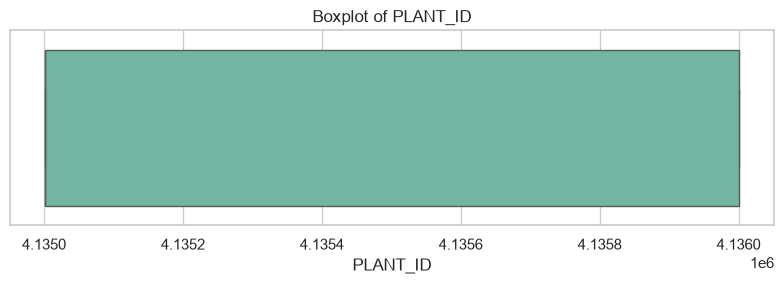

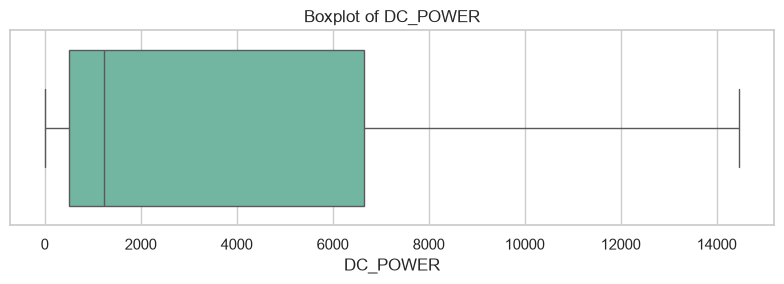

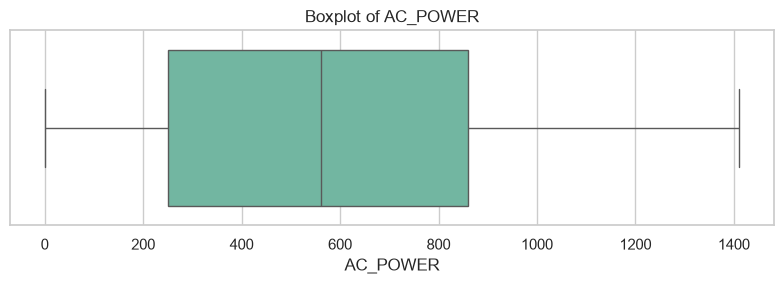

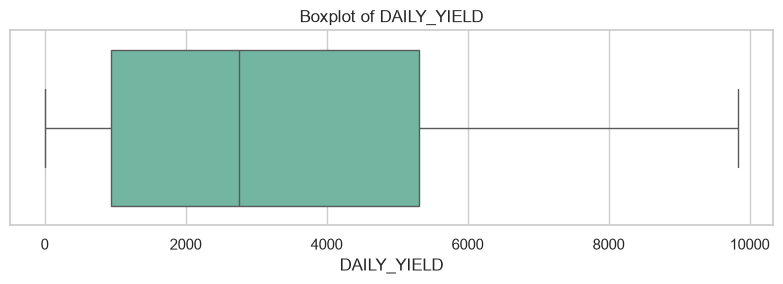

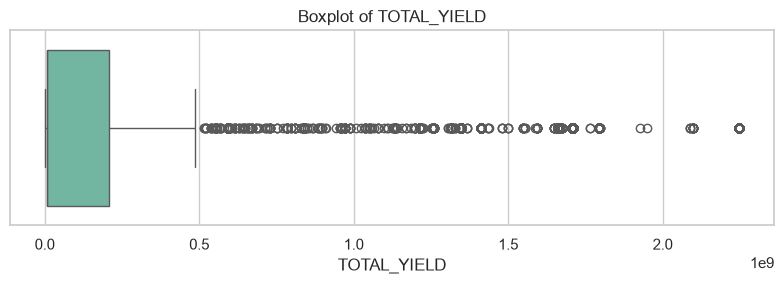

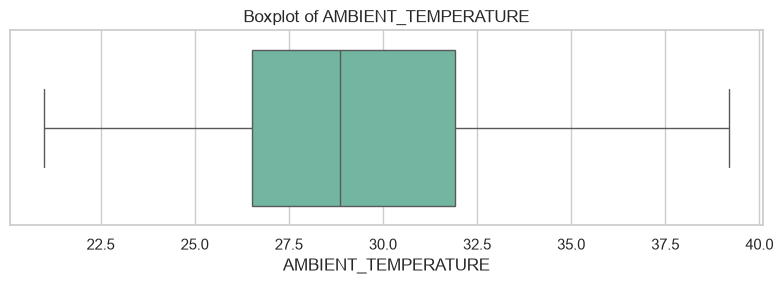

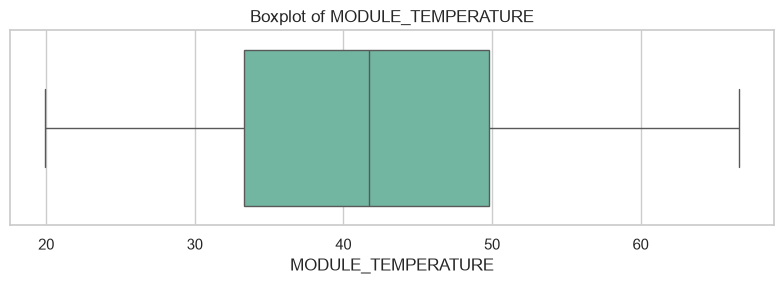

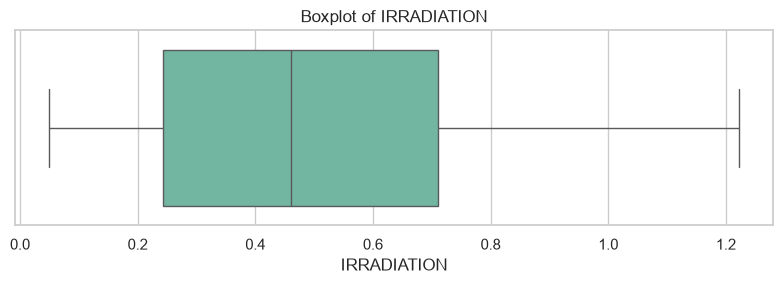

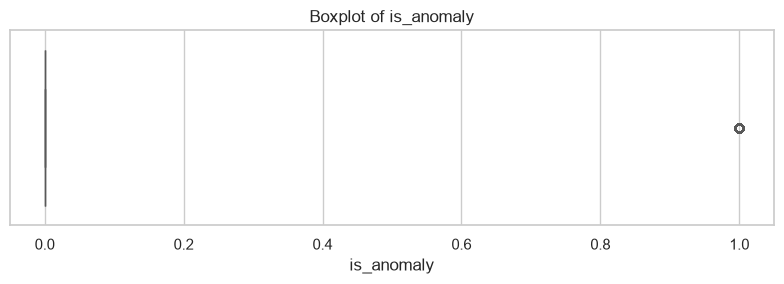

In [37]:
numeric_cols = data.select_dtypes(include=np.number).columns


# Boxplots for numerical features
for col in numeric_cols:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=data[col])
    plt.title(f"Boxplot of {col}")
    plt.tight_layout()
    plt.show()



There are 0 null values

0 duplicates

there are imbalanced data

wrong data type of DATE_TIME column

outlier in TOTAL_YIELD but it's real data

# EDA

**How balanced is the dataset between normal and anomalous records?**

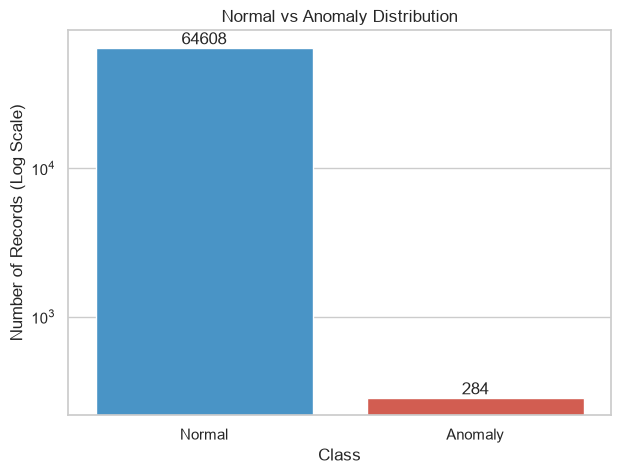

In [38]:
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=data, x="is_anomaly", hue="is_anomaly",
                   palette=["#3498DB", "#E74C3C"], legend=False)
ax.set_yscale("log")
ax.bar_label(ax.containers[0], fmt="%d")
ax.bar_label(ax.containers[1], fmt="%d")

plt.xticks([0, 1], ["Normal", "Anomaly"])
plt.title("Normal vs Anomaly Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Records (Log Scale)")
plt.show()

**How does solar power generation change throughout the day?**

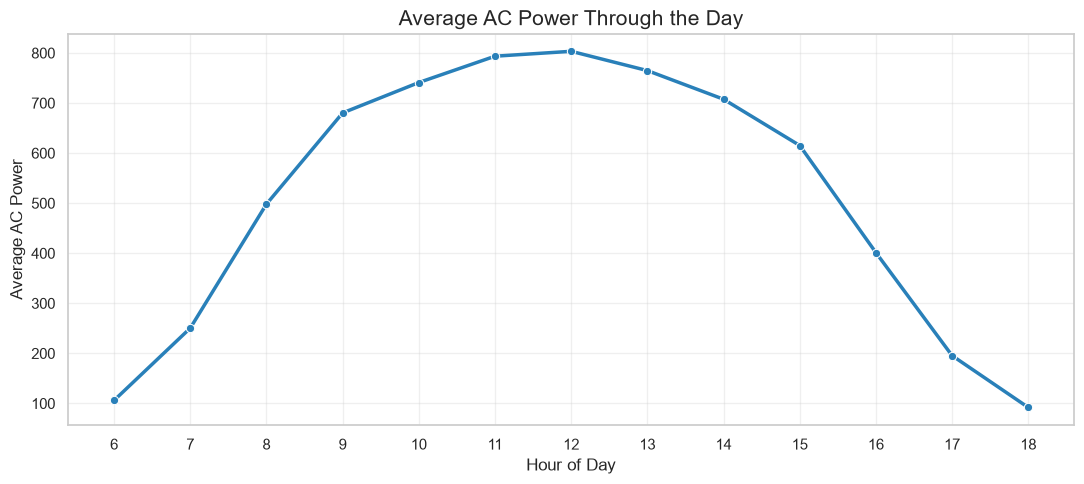

,hour,AC_POWER
0,6,106.121612
1,7,250.476046
2,8,498.136916
3,9,680.316302
4,10,741.006522
5,11,793.583360
6,12,803.358434
7,13,764.849507
8,14,707.629236
9,15,615.199515


In [39]:
data["hour"] = data["DATE_TIME"].dt.hour

hourly_power = (data.groupby("hour")["AC_POWER"].mean().reset_index())

plt.figure(figsize=(11, 5))
sns.lineplot(data=hourly_power,x="hour",
    y="AC_POWER",marker="o",
    color="#2980B9",linewidth=2.5)

plt.title("Average AC Power Through the Day", fontsize=15)
plt.xlabel("Hour of Day")
plt.ylabel("Average AC Power")
plt.xticks(hourly_power["hour"])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(hourly_power)


**What is the relationship between solar irradiation and AC power**

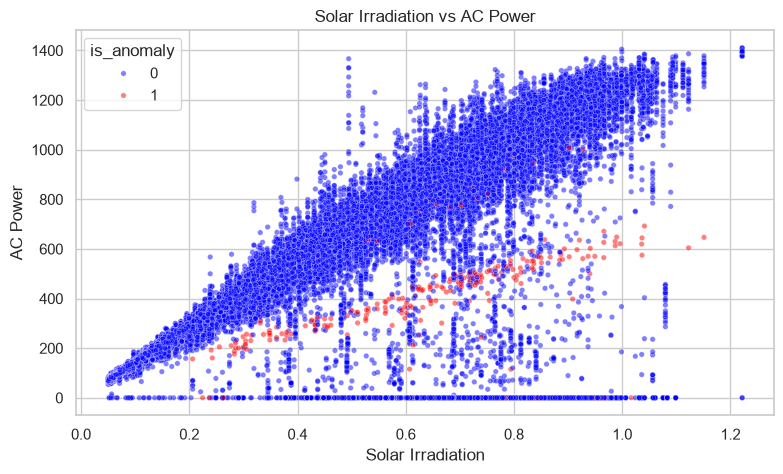

In [40]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=data, x="IRRADIATION", y="AC_POWER",hue="is_anomaly", palette={0: "blue", 1: "red"},alpha=0.5, s=15)
plt.title("Solar Irradiation vs AC Power")
plt.xlabel("Solar Irradiation")
plt.ylabel("AC Power")
plt.show()

**At what hours do anomalies occur most frequently**

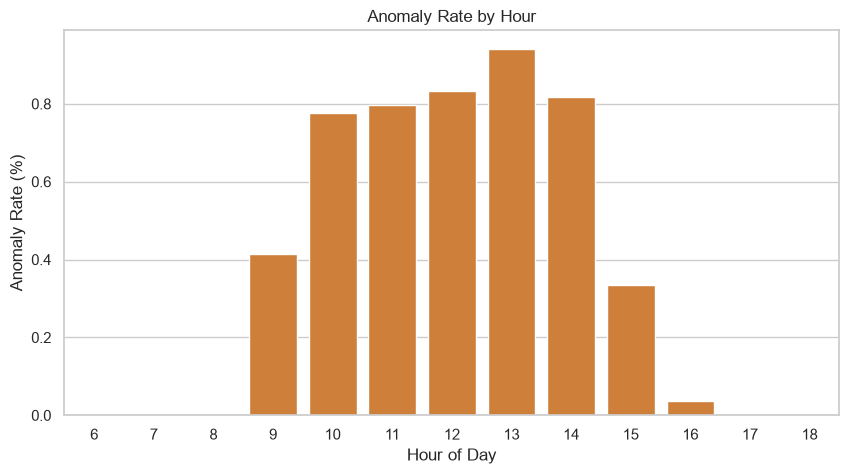

In [41]:
hourly = data.groupby("hour")["is_anomaly"].mean() * 100
plt.figure(figsize=(10, 5))
sns.barplot(x=hourly.index, y=hourly.values, color="#E67E22")
plt.title("Anomaly Rate by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Anomaly Rate (%)")
plt.show()

**How does the anomaly rate change over time**

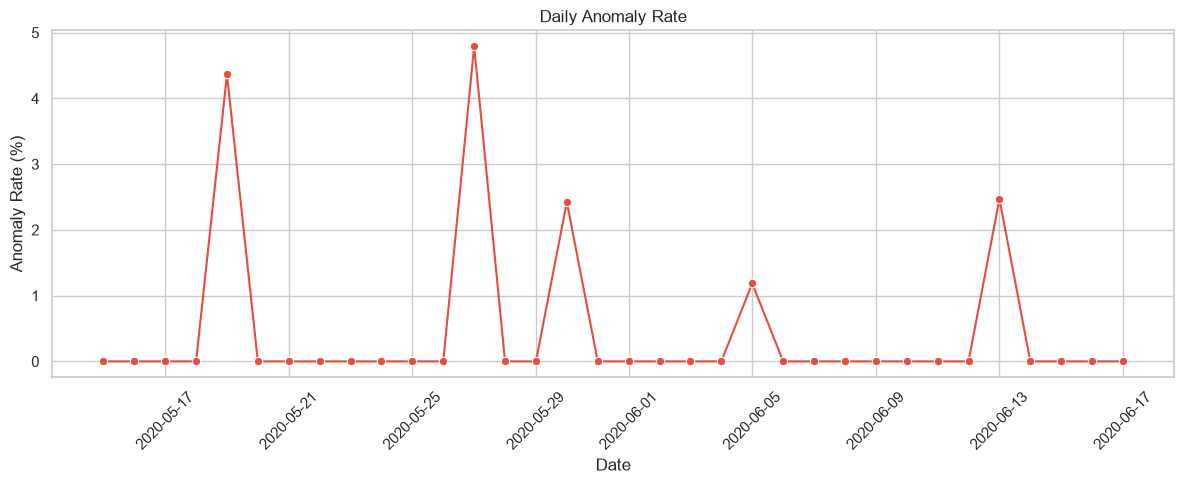

In [42]:
daily = data.groupby(data["DATE_TIME"].dt.date)["is_anomaly"].mean() * 100
plt.figure(figsize=(12, 5))
sns.lineplot(x=daily.index, y=daily.values, marker="o", color="#E74C3C")
plt.title("Daily Anomaly Rate")
plt.xlabel("Date")
plt.ylabel("Anomaly Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Which inverters have the highest anomaly rates**

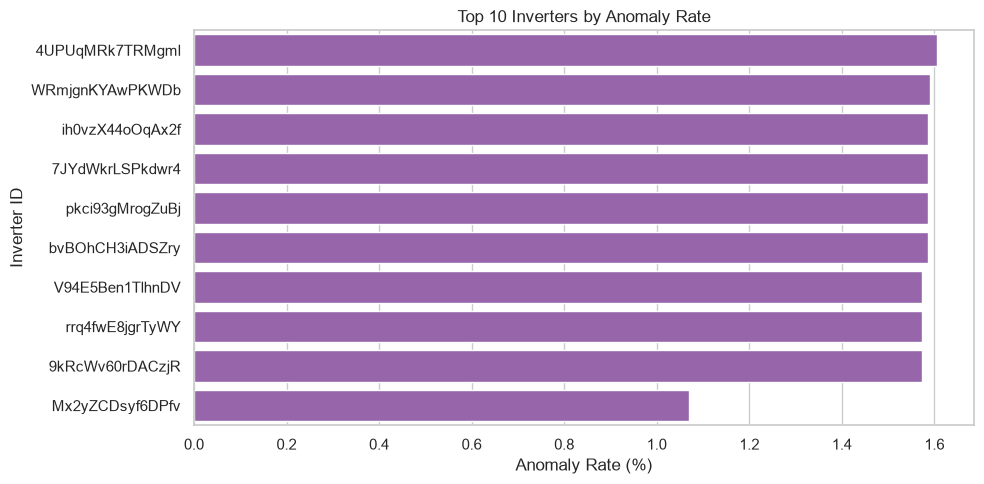

In [43]:
inverter_rates = (data.groupby("SOURCE_KEY")["is_anomaly"].mean().mul(100).sort_values(ascending=False).head(10))
plt.figure(figsize=(10, 5))
sns.barplot(x=inverter_rates.values,y=inverter_rates.index,color="#9B59B6")
plt.title("Top 10 Inverters by Anomaly Rate")
plt.xlabel("Anomaly Rate (%)")
plt.ylabel("Inverter ID")
plt.tight_layout()
plt.show()

**Does module temperature differ between normal and anomalous records?**

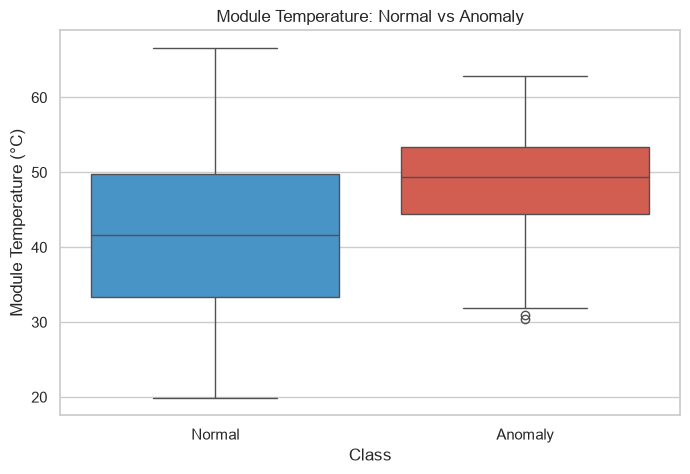

In [44]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=data,
    x="is_anomaly",
    y="MODULE_TEMPERATURE",
    hue="is_anomaly",
    palette=["#3498DB", "#E74C3C"],
    legend=False)
plt.xticks([0, 1], ["Normal","Anomaly"])
plt.title("Module Temperature: Normal vs Anomaly")
plt.xlabel("Class")
plt.ylabel("Module Temperature (°C)")
plt.show()

**Which numerical features are most strongly correlated?**

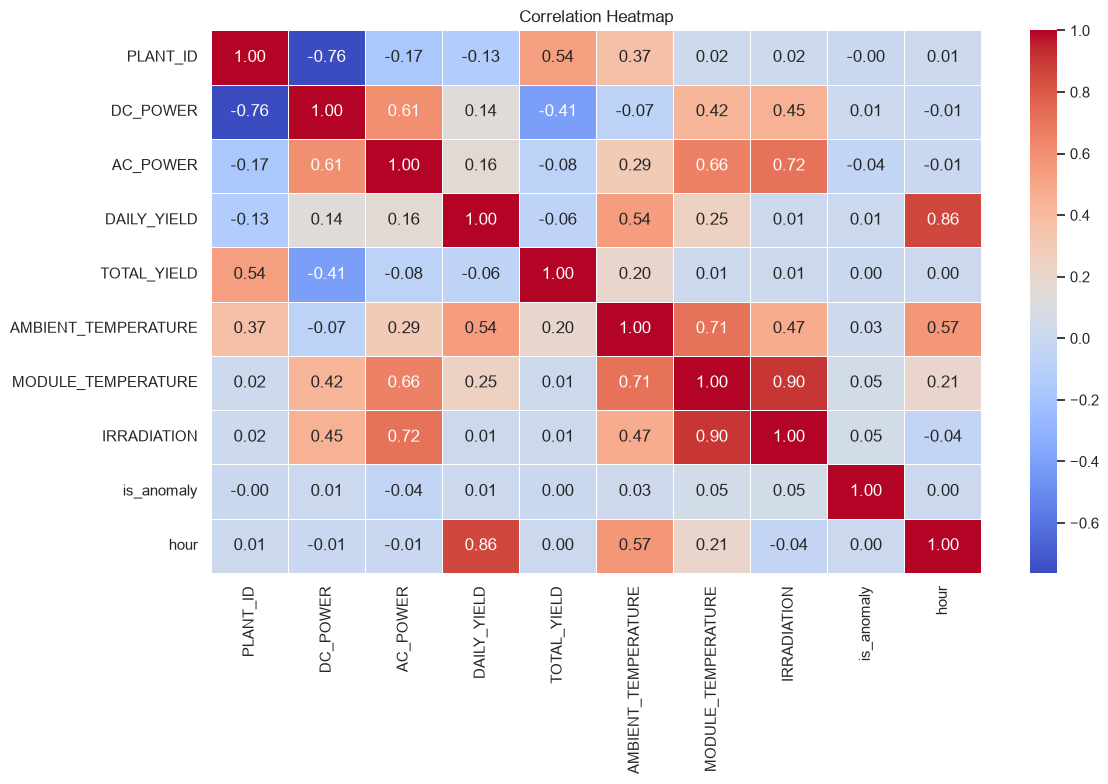

In [45]:
numeric_df = data.select_dtypes(include="number")
plt.figure(figsize=(12, 8))
sns.heatmap(numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# Data Cleaning

In [46]:
df=data.copy() # take copy of data to make cleaning
df.head()

,DATE_TIME,SOURCE_KEY,PLANT_ID,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,SOURCE_KEY_weather,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,is_anomaly,hour
0,2020-05-15 06:45:00,1BY6WEcLGh8j5v7,4135001,1224.750000,119.275000,34.875000,6259593.875,HmiyD2TTLFNqkNe,24.218990,24.442444,0.095394,0,6
1,2020-05-15 07:00:00,1BY6WEcLGh8j5v7,4135001,1734.571429,170.014286,72.714286,6259631.714,HmiyD2TTLFNqkNe,24.537398,27.185653,0.141940,0,7
2,2020-05-15 07:15:00,1BY6WEcLGh8j5v7,4135001,1856.375000,181.937500,116.250000,6259675.250,HmiyD2TTLFNqkNe,24.815960,28.888478,0.154713,0,7
3,2020-05-15 07:30:00,1BY6WEcLGh8j5v7,4135001,1842.285714,180.585714,162.428571,6259721.429,HmiyD2TTLFNqkNe,24.988790,29.605644,0.148799,0,7
4,2020-05-15 07:45:00,1BY6WEcLGh8j5v7,4135001,1877.875000,184.062500,206.375000,6259765.375,HmiyD2TTLFNqkNe,25.216180,29.547111,0.144793,0,7


## Feature Engineering

In [47]:

# 2. Sort before calculating lag features
df = df.sort_values(
    ["SOURCE_KEY", "DATE_TIME"]
).reset_index(drop=True)

# 3. Time features
df["month"] = df["DATE_TIME"].dt.month

# 4. Temperature difference
df["temperature_difference"] = (
    df["MODULE_TEMPERATURE"] -
    df["AMBIENT_TEMPERATURE"]
)

# 5. Power difference
df["power_difference"] = (
    df["DC_POWER"] - df["AC_POWER"]
)

# 6. Zero-value indicators
df["zero_dc_power"] = (df["DC_POWER"] == 0).astype(int) # night shifts
df["zero_irradiation"] = (df["IRRADIATION"] == 0).astype(int) # night shifts

# 7. Ratio
df["dc_power_per_irradiation"] = (
    df["DC_POWER"] /
    df["IRRADIATION"].replace(0, np.nan)
)

# 8. Previous DC power and change
df["previous_dc_power"] = (
    df.groupby("SOURCE_KEY")["DC_POWER"].shift(1)
)

df["dc_power_change"] = (
    df["DC_POWER"] - df["previous_dc_power"]
)

# 9. Previous daily yield and change
df["previous_daily_yield"] = (
    df.groupby("SOURCE_KEY")["DAILY_YIELD"].shift(1)
)

df["daily_yield_change"] = (
    df["DAILY_YIELD"] - df["previous_daily_yield"]
)

print("Missing values:\n",df.isnull().sum().sort_values(ascending=False))



Missing values:
 previous_daily_yield        44
dc_power_change             44
previous_dc_power           44
daily_yield_change          44
DATE_TIME                    0
SOURCE_KEY                   0
PLANT_ID                     0
TOTAL_YIELD                  0
DAILY_YIELD                  0
AC_POWER                     0
DC_POWER                     0
SOURCE_KEY_weather           0
AMBIENT_TEMPERATURE          0
MODULE_TEMPERATURE           0
IRRADIATION                  0
temperature_difference       0
month                        0
hour                         0
is_anomaly                   0
dc_power_per_irradiation     0
zero_irradiation             0
zero_dc_power                0
power_difference             0
dtype: int64


In [48]:
print("New dataset shape:", df.shape)
display(df.head())

New dataset shape: (64892, 23)


,DATE_TIME,SOURCE_KEY,PLANT_ID,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,SOURCE_KEY_weather,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,...,month,temperature_difference,power_difference,zero_dc_power,zero_irradiation,dc_power_per_irradiation,previous_dc_power,dc_power_change,previous_daily_yield,daily_yield_change
0,2020-05-15 06:45:00,1BY6WEcLGh8j5v7,4135001,1224.750000,119.275000,34.875000,6259593.875,HmiyD2TTLFNqkNe,24.218990,24.442444,...,5,0.223454,1105.475000,0,0,12838.796741,NaN,NaN,NaN,NaN
1,2020-05-15 07:00:00,1BY6WEcLGh8j5v7,4135001,1734.571429,170.014286,72.714286,6259631.714,HmiyD2TTLFNqkNe,24.537398,27.185653,...,5,2.648254,1564.557143,0,0,12220.417157,1224.750000,509.821429,34.875000,37.839286
2,2020-05-15 07:15:00,1BY6WEcLGh8j5v7,4135001,1856.375000,181.937500,116.250000,6259675.250,HmiyD2TTLFNqkNe,24.815960,28.888478,...,5,4.072518,1674.437500,0,0,11998.855242,1734.571429,121.803571,72.714286,43.535714
3,2020-05-15 07:30:00,1BY6WEcLGh8j5v7,4135001,1842.285714,180.585714,162.428571,6259721.429,HmiyD2TTLFNqkNe,24.988790,29.605644,...,5,4.616854,1661.700000,0,0,12381.022827,1856.375000,-14.089286,116.250000,46.178571
4,2020-05-15 07:45:00,1BY6WEcLGh8j5v7,4135001,1877.875000,184.062500,206.375000,6259765.375,HmiyD2TTLFNqkNe,25.216180,29.547111,...,5,4.330931,1693.812500,0,0,12969.339448,1842.285714,35.589286,162.428571,43.946429


Splitting data

In [49]:
X = df.drop(
    columns=["DATE_TIME", "is_anomaly", "SOURCE_KEY",
             "SOURCE_KEY_weather", "PLANT_ID"],
    errors="ignore"
)

y = df["is_anomaly"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

Imputation after splitting (to undo data leakage)

In [50]:
from sklearn.impute import SimpleImputer

# 1. Replace infinity with NaN
X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

# 2. Create imputer
imputer = SimpleImputer(strategy="median")

# 3. Fit on training data only
X_train = imputer.fit_transform(X_train)

# 4. Apply to  x-test
X_test = imputer.transform(X_test)

# 5. Check null
print("Remaining NaN in train:", np.isnan(X_train).sum())
print("Remaining NaN in test:", np.isnan(X_test).sum())

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Remaining NaN in train: 0
Remaining NaN in test: 0
Train shape: (51913, 18)
Test shape: (12979, 18)


# Modeling

In [51]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold,RandomizedSearchCV
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,f1_score,recall_score,precision_score,
    roc_auc_score,roc_curve,
    RocCurveDisplay
)

### training data

1- logisitc regression

In [52]:
lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

lr_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,18
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [53]:
lr_pred = lr_model.predict(X_test)
lr_prob = lr_model.predict_proba(X_test)[:, 1]

              precision    recall  f1-score   support

           0       1.00      0.93      0.96     12922
           1       0.05      0.95      0.10        57

    accuracy                           0.93     12979
   macro avg       0.53      0.94      0.53     12979
weighted avg       1.00      0.93      0.96     12979

Confusion Matrix:
 [[11976   946]
 [    3    54]]


<Axes: >

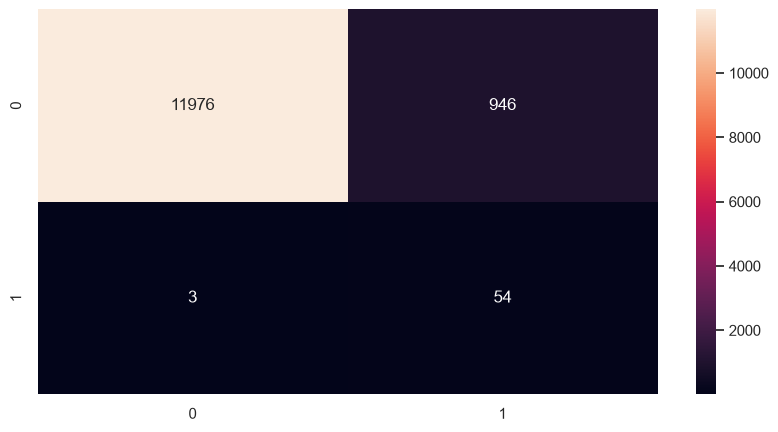

In [54]:
print(classification_report(y_test, lr_pred, zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, lr_pred))
sns.heatmap(confusion_matrix(y_test, lr_pred), annot=True, fmt="d")


In [55]:
print("PR-AUC:", average_precision_score(y_test, lr_prob))
print("ROC-AUC:", roc_auc_score(y_test, lr_prob))
print('f1-score',f1_score(y_test, lr_pred, zero_division=0))

PR-AUC: 0.12725972826867757
ROC-AUC: 0.9627943097179568
f1-score 0.1021759697256386


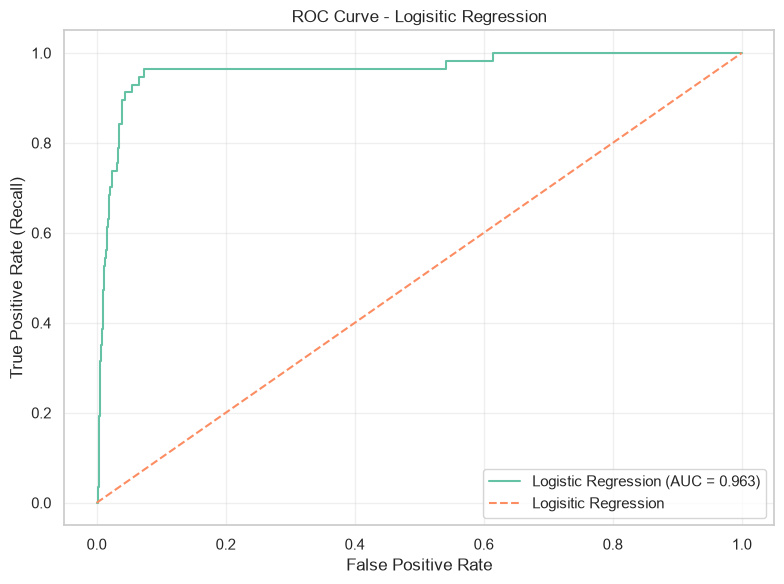

In [56]:

# Calculate ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, lr_prob)
roc_auc = roc_auc_score(y_test, lr_prob)

# Plot
plt.figure(figsize=(8, 6))

plt.plot(
    fpr, tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Logisitic Regression"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve - Logisitic Regression")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

2- Random Forest

In [57]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced", # to imbalanced data
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

In [58]:
rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     12922
           1       1.00      0.91      0.95        57

    accuracy                           1.00     12979
   macro avg       1.00      0.96      0.98     12979
weighted avg       1.00      1.00      1.00     12979

Confusion Matrix:
[[12922     0]
 [    5    52]]


<Axes: >

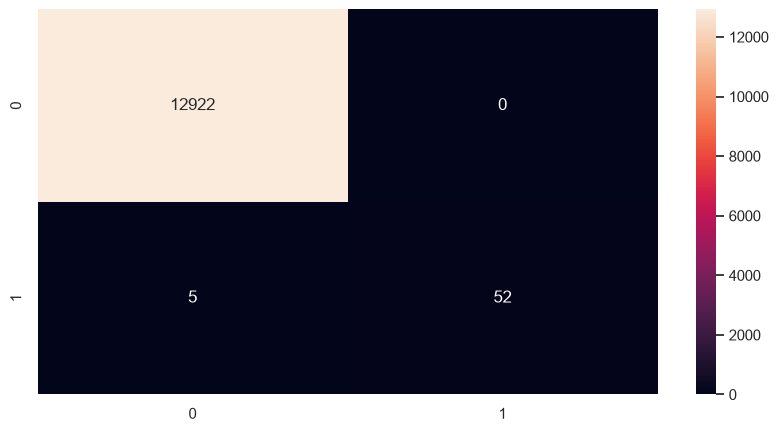

In [59]:
print("Classification Report:")
print(classification_report(y_test, rf_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_pred))
sns.heatmap(confusion_matrix(y_test, rf_pred), annot=True, fmt="d")


In [60]:
print("ROC-AUC:", roc_auc_score(y_test, rf_prob))
print("PR-AUC:", average_precision_score(y_test, rf_prob))
print('f1-score',f1_score(y_test, rf_pred, zero_division=0))

ROC-AUC: 0.9998560865869984
PR-AUC: 0.986085066689538
f1-score 0.9541284403669725


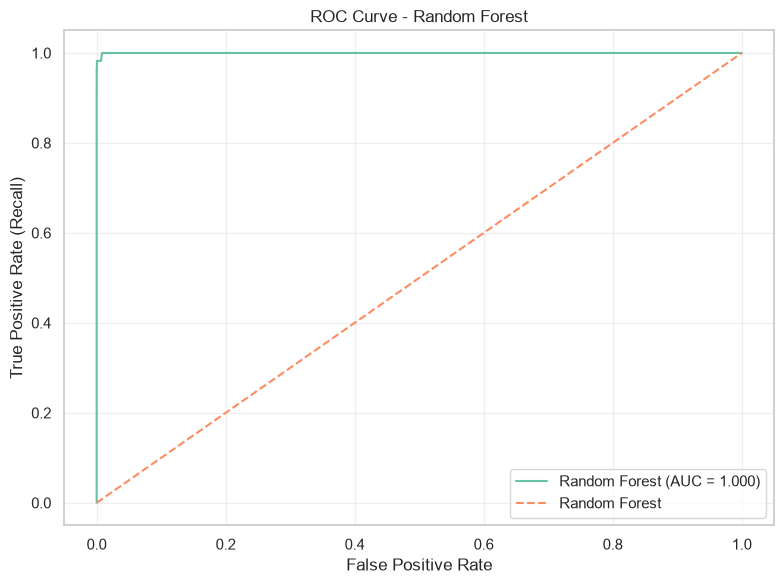

In [61]:
# Calculate ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, rf_prob)
roc_auc = roc_auc_score(y_test, rf_prob)

# Plot
plt.figure(figsize=(8, 6))

plt.plot(
    fpr, tpr,
    label=f"Random Forest (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Random Forest"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve - Random Forest")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

3- fune-tuing Random Forest

In [62]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from scipy.stats import randint

tuned_rf = RandomForestClassifier(
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

param_dist_rf = {
    "n_estimators": randint(100, 501),
    "max_depth": [None, 10, 20, 30, 40],
    "min_samples_split": randint(2, 21),
    "min_samples_leaf": randint(1, 11)
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_search = RandomizedSearchCV(
    estimator=tuned_rf,
    param_distributions=param_dist_rf,
    n_iter=30,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, y_train)

best_rf = rf_search.best_estimator_

print("Best parameters:", rf_search.best_params_)
print("Best CV F1:", rf_search.best_score_)



Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best parameters: {'max_depth': 30, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 147}
Best CV F1: 0.8924177505386686


In [63]:
best_rf = rf_search.best_estimator_
print("Best Parameters:", rf_search.best_params_)
print("Best CV f1 score:", rf_search.best_score_)

tuned_rf_pred = best_rf.predict(X_test)
tuned_rf_prob = best_rf.predict_proba(X_test)[:, 1]




Best Parameters: {'max_depth': 30, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 147}
Best CV f1 score: 0.8924177505386686


              precision    recall  f1-score   support

           0       1.00      1.00      1.00     12922
           1       0.98      0.89      0.94        57

    accuracy                           1.00     12979
   macro avg       0.99      0.95      0.97     12979
weighted avg       1.00      1.00      1.00     12979



<Axes: >

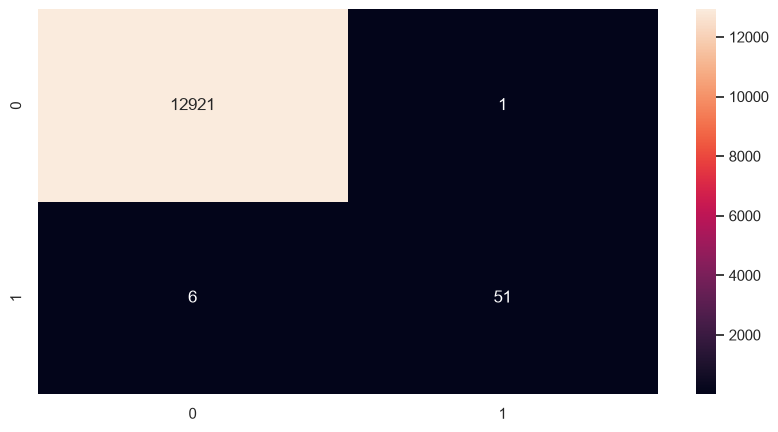

In [64]:
print(classification_report(
    y_test, tuned_rf_pred, zero_division=0
))
sns.heatmap(confusion_matrix(y_test, tuned_rf_pred), annot=True, fmt="d")


In [65]:
print("Test PR-AUC:",average_precision_score(y_test, tuned_rf_prob))
print('f1-score',f1_score(y_test, tuned_rf_pred, zero_division=0))
print('recall',recall_score(y_test, tuned_rf_pred, zero_division=0))
print('precision',precision_score(y_test, tuned_rf_pred, zero_division=0))

Test PR-AUC: 0.9837613559530238
f1-score 0.9357798165137615
recall 0.8947368421052632
precision 0.9807692307692307


BaseLine-xgboost

In [66]:
# Calculate class imbalance using training data only
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / max(positive_count, 1)

print("Normal samples:", negative_count)
print("Anomaly samples:", positive_count)
print("Scale pos weight:", round(scale_pos_weight, 2))


Normal samples: 51686
Anomaly samples: 227
Scale pos weight: 227.69


In [67]:
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)
xgb_model.fit(X_train, y_train)


,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [68]:
xgb_pred = xgb_model.predict(X_test)
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     12922
           1       0.93      0.96      0.95        57

    accuracy                           1.00     12979
   macro avg       0.97      0.98      0.97     12979
weighted avg       1.00      1.00      1.00     12979

Confusion Matrix:
 [[12918     4]
 [    2    55]]


<Axes: >

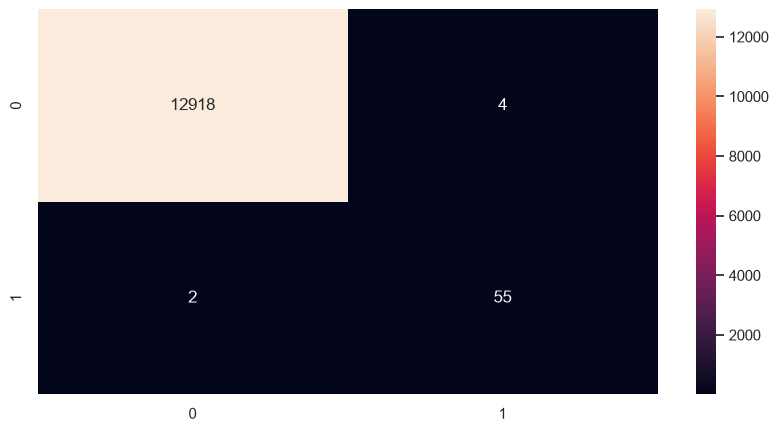

In [69]:
print(classification_report(y_test, xgb_pred, zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, xgb_pred))
sns.heatmap(confusion_matrix(y_test, xgb_pred), annot=True, fmt="d")


In [70]:
print("PR-AUC:", average_precision_score(y_test, xgb_prob))
print("ROC-AUC:", roc_auc_score(y_test, xgb_prob))
print('f1score:',f1_score(y_test, xgb_pred))

PR-AUC: 0.9831520221809326
ROC-AUC: 0.9996782313313077
f1score: 0.9482758620689655


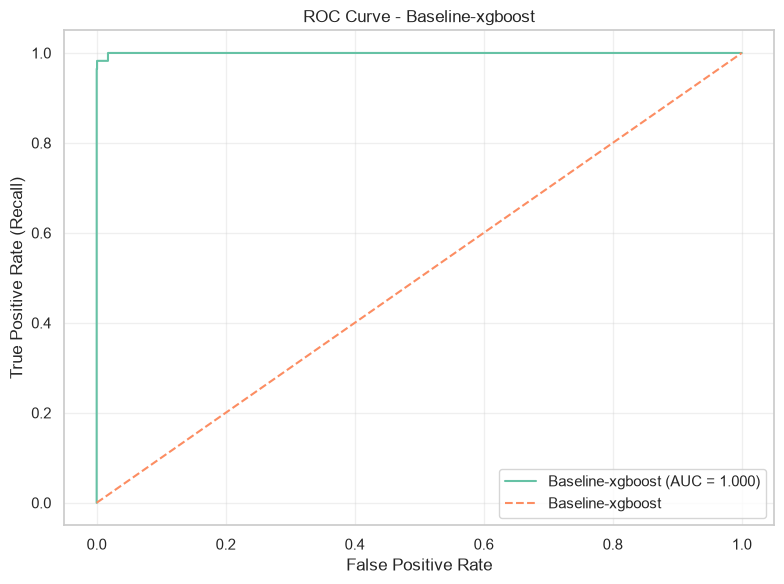

In [71]:
# Calculate ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, xgb_prob)
roc_auc = roc_auc_score(y_test, xgb_prob)

# Plot
plt.figure(figsize=(8, 6))

plt.plot(
    fpr, tpr,
    label=f"Baseline-xgboost (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Baseline-xgboost"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve - Baseline-xgboost")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Fine-tuning XGBoost

In [72]:
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import randint, uniform

xgb_base = XGBClassifier(
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=1
)

param_dist_xgb = {
    "n_estimators": randint(100, 501),
    "max_depth": randint(3, 10),
    "learning_rate": uniform(0.01, 0.19),
    "subsample": uniform(0.6, 0.4),
    "colsample_bytree": uniform(0.6, 0.4),
    "min_child_weight": randint(1, 11),
    "gamma": uniform(0, 0.5),
    "reg_lambda": uniform(0.5, 5.0)
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

xgb_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_dist_xgb,
    n_iter=30,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

xgb_search.fit(X_train, y_train)

best_xgb = xgb_search.best_estimator_

print("Best parameters:", xgb_search.best_params_)
print("Best CV F1:", xgb_search.best_score_)



Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best parameters: {'colsample_bytree': np.float64(0.9990961940195767), 'gamma': np.float64(0.1333905071376425), 'learning_rate': np.float64(0.19555684160820405), 'max_depth': 6, 'min_child_weight': 6, 'n_estimators': 442, 'reg_lambda': np.float64(1.8932323211830573), 'subsample': np.float64(0.9633063543866615)}
Best CV F1: 0.9477285519163251


              precision    recall  f1-score   support

           0       1.00      1.00      1.00     12922
           1       0.93      0.96      0.95        57

    accuracy                           1.00     12979
   macro avg       0.97      0.98      0.97     12979
weighted avg       1.00      1.00      1.00     12979

Confusion Matrix:
 [[12918     4]
 [    2    55]]


<Axes: >

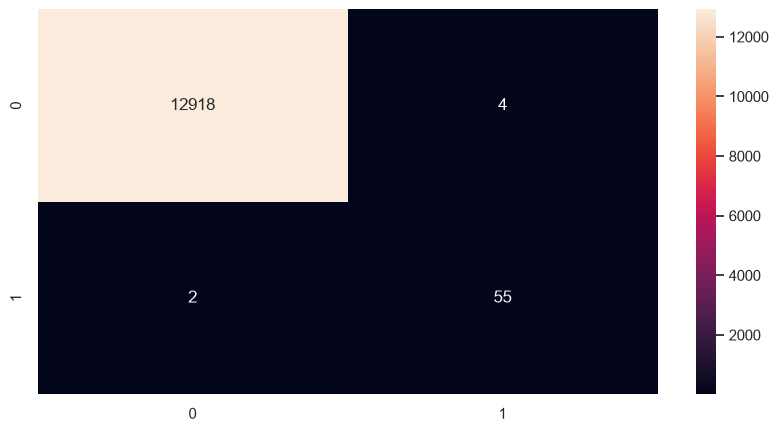

In [73]:
tuned_xgb_pred = best_xgb.predict(X_test)
tuned_xgb_prob = best_xgb.predict_proba(X_test)[:, 1]

print(classification_report(
    y_test, tuned_xgb_pred, zero_division=0
))

print("Confusion Matrix:\n", confusion_matrix(y_test, tuned_xgb_pred))
sns.heatmap(confusion_matrix(y_test, tuned_xgb_pred), annot=True, fmt="d")

In [74]:
print("PR-AUC:", average_precision_score(y_test, tuned_xgb_prob))
print("ROC-AUC:", roc_auc_score(y_test, tuned_xgb_prob))
print('f1score:', f1_score(y_test, tuned_xgb_pred))

PR-AUC: 0.9929228809729245
ROC-AUC: 0.999956554441358
f1score: 0.9482758620689655


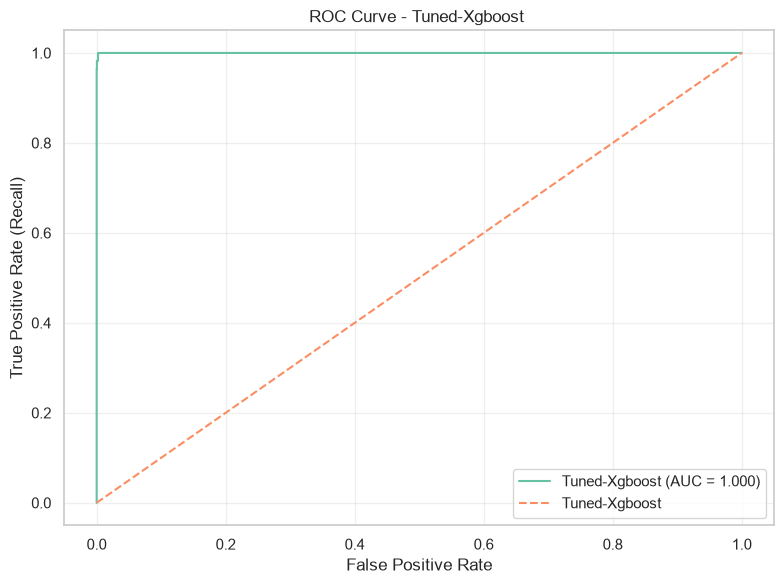

In [75]:
# Calculate ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, tuned_xgb_prob)
roc_auc = roc_auc_score(y_test, tuned_xgb_prob)

# Plot
plt.figure(figsize=(8, 6))

plt.plot(
    fpr, tpr,
    label=f"Tuned-Xgboost (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Tuned-Xgboost "
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve - Tuned-Xgboost ")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Feature importance for XGBoost

                     Feature  Importance
17                     month    0.229779
1                   AC_POWER    0.215078
9              zero_dc_power    0.114924
6                IRRADIATION    0.091705
10          zero_irradiation    0.063526
3                TOTAL_YIELD    0.057915
2                DAILY_YIELD    0.043498
11  dc_power_per_irradiation    0.031369
5         MODULE_TEMPERATURE    0.029910
0                   DC_POWER    0.027360
7     temperature_difference    0.024713
8           power_difference    0.019088
16                      hour    0.016610
4        AMBIENT_TEMPERATURE    0.013485
13           dc_power_change    0.010743
15        daily_yield_change    0.006451
14      previous_daily_yield    0.003846
12         previous_dc_power    0.000000


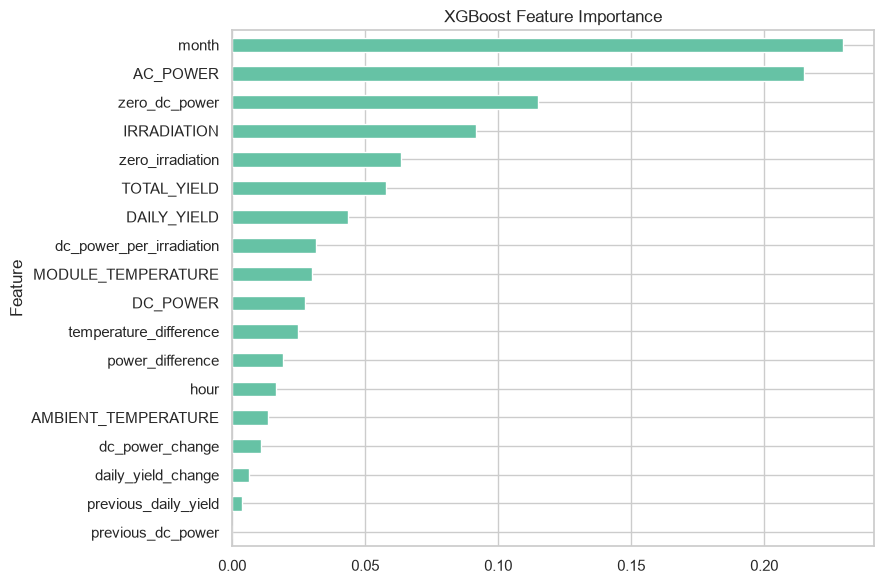

In [76]:
feature_names = list(imputer.feature_names_in_)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": best_xgb.feature_importances_
}).sort_values("Importance", ascending=False)

print(feature_importance)

feature_importance.plot(
    x="Feature",
    y="Importance",
    kind="barh",
    figsize=(9, 6),
    legend=False,
    title="XGBoost Feature Importance"
)

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Compare all models

In [77]:
def evaluate_model(name, model, X_val, y_val):
    y_pred = model.predict(X_val)
    y_prob = model.predict_proba(X_val)[:, 1]

    return {
        "Model": name,
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1": f1_score(y_val, y_pred, zero_division=0),
        "PR-AUC": average_precision_score(y_val, y_prob),
        "ROC-AUC": roc_auc_score(y_val, y_prob)
    }


models_to_compare = {
    'Logistic Regression': lr_model,
    'Random Forest': rf_model,
    'Tuned Random Forest': best_rf,
    'XGBoost Baseline': xgb_model,
    "XGBoost Tuned": best_xgb
}



In [78]:
comparison = pd.DataFrame([
    evaluate_model(name, model, X_test, y_test)
    for name, model in models_to_compare.items()
])

comparison = comparison.sort_values("F1", ascending=False)

print(comparison.round(4).head())

                 Model  Precision  Recall      F1  PR-AUC  ROC-AUC
1        Random Forest     1.0000  0.9123  0.9541  0.9861   0.9999
4        XGBoost Tuned     0.9322  0.9649  0.9483  0.9929   1.0000
3     XGBoost Baseline     0.9322  0.9649  0.9483  0.9832   0.9997
2  Tuned Random Forest     0.9808  0.8947  0.9358  0.9838   0.9998
0  Logistic Regression     0.0540  0.9474  0.1022  0.1273   0.9628


The application exports the tuned XGBoost model (`best_xgb`), not the baseline. Earlier test-set comparison is exploratory and must not be described as independent model selection. See the final verification cells for metrics and explanations computed from the exact exported model.

In [81]:
import json
import joblib
import sklearn
import xgboost
from pathlib import Path

output = Path(
    str(ROOT / 'data/processed/Anomaly/anomaly_export')
)
output = ROOT/"reports/anomaly_notebook_export"
output.mkdir(parents=True, exist_ok=True)

# حفظ الموديل والـ Imputer المتدرّب
best_xgb.save_model(output / "anomaly_model.json")
joblib.dump(imputer, output / "imputer.joblib")

# حفظ ترتيب الأعمدة وإصدارات المكتبات
features = list(imputer.feature_names_in_)

metadata = {
    "features": features,
    "sklearn_version": sklearn.__version__,
    "xgboost_version": xgboost.__version__,
}

(output / "metadata.json").write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8",
)

# حفظ مثال للمدخلات بنفس ترتيب التدريب
X.loc[:, features].head(2).to_json(
    output / "example_rows.json",
    orient="records",
    indent=2,
)

# ضغط الملفات لتسهيل رفعها
import shutil

zip_path = shutil.make_archive(
    str(output),
    "zip",
    root_dir=output.parent,
    base_dir=output.name,
)

print(f"تم التصدير والضغط:\n{zip_path}")

تم التصدير والضغط:
D:\sic_1\Solar-AI-Platform-Renewable-Generation-Yield-Grid-Load-Anomaly-Intelligence\data\processed\Anomaly\anomaly_export.zip


## Deployment verification and chronological diagnostic
The original deployed weights remain unchanged. The separate chronological refit is diagnostic only. Synthetic labels and prior parameter selection limit both evaluations. Run the next cell to reproduce the audit and native TreeSHAP summary.

In [1]:
import runpy
runpy.run_path(str(ROOT / 'scripts/verify_anomaly.py'), run_name='__main__')


{
  "deployed_model_sha256": "e2e7835a4d6371cef8873b12c1ab011a882adea821f3f0d2ee9e21d27bbe8a7b",
  "label_source": "Synthetic faults injected by Data Cleaning notebook; not verified human fault annotations",
  "original_random_split": {
    "confusion_matrix": [
      [
        12918,
        4
      ],
      [
        2,
        55
      ]
    ],
    "precision": 0.9322033898305084,
    "recall": 0.9649122807017544,
    "F1": 0.9482758620689655,
    "average_precision": 0.9929228809729245,
    "rows": 12979,
    "positives": 57
  },
  "chronological_diagnostic": {
    "cutoff": "2020-06-11 00:00:00",
    "training_rows": 51032,
    "test_rows": 13860,
    "train_only_imputer": true,
    "deployment_changed": false,
    "metrics": {
      "confusion_matrix": [
        [
          13806,
          4
        ],
        [
          19,
          31
        ]
      ],
      "precision": 0.8857142857142857,
      "recall": 0.62,
      "F1": 0.7294117647058823,
      "average_precision": 0.7

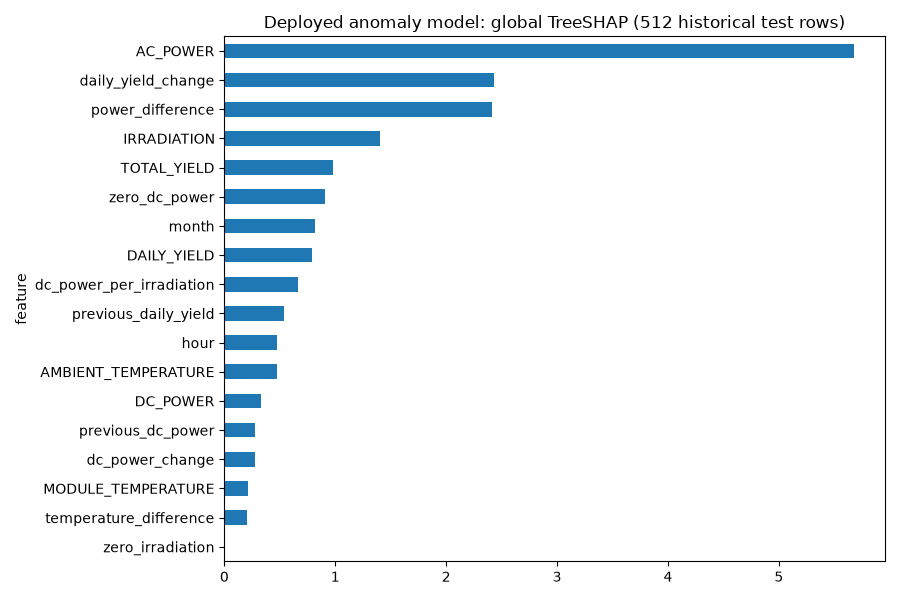

In [2]:
import json
review = json.loads((ROOT / 'reports/anomaly_review/evaluation.json').read_text())
print(json.dumps(review, indent=2))
importance = pd.read_csv(ROOT / 'reports/anomaly_review/global_shap.csv')
importance.sort_values('mean_absolute_SHAP_log_odds').plot.barh(x='feature', y='mean_absolute_SHAP_log_odds', figsize=(9, 6), legend=False, title='Deployed anomaly model: global TreeSHAP (512 historical test rows)')
plt.tight_layout()
plt.show()
